In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_csv = pd.read_csv("sales.csv")
print("CSV shape:", df_csv.shape)
df_csv.head()

CSV shape: (125, 6)


,OrderID,Product,Category,Quantity,Price,Region
0,1,Phone,Electronics,2,1499.0,South
1,2,Headphones,Accessories,1,2499.0,South
2,3,Laptop,Accessories,2,1499.0,South
3,4,Laptop,Accessories,1,999.0,North
4,5,Headphones,Accessories,2,999.0,East


In [3]:
df_excel = pd.read_excel("sales.xlsx")
print("Excel shape:", df_excel.shape)
df_excel.head()

Excel shape: (125, 6)


,OrderID,Product,Category,Quantity,Price,Region
0,1,Phone,Electronics,2,1499.0,South
1,2,Headphones,Accessories,1,2499.0,South
2,3,Laptop,Accessories,2,1499.0,South
3,4,Laptop,Accessories,1,999.0,North
4,5,Headphones,Accessories,2,999.0,East


In [4]:
df_json = pd.read_json("sales.json")
print("JSON shape:", df_json.shape)
df_json.head()

JSON shape: (125, 6)


,OrderID,Product,Category,Quantity,Price,Region
0,1,Phone,Electronics,2,1499.0,South
1,2,Headphones,Accessories,1,2499.0,South
2,3,Laptop,Accessories,2,1499.0,South
3,4,Laptop,Accessories,1,999.0,North
4,5,Headphones,Accessories,2,999.0,East


In [5]:
df_csv.info()

<class 'pandas.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   OrderID   125 non-null    int64  
 1   Product   125 non-null    str    
 2   Category  125 non-null    str    
 3   Quantity  125 non-null    int64  
 4   Price     117 non-null    float64
 5   Region    125 non-null    str    
dtypes: float64(1), int64(2), str(3)
memory usage: 6.0 KB


In [6]:
print("Missing values in each column:")
print(df_csv.isnull().sum())
print()
print("Duplicate rows:", df_csv.duplicated().sum())

Missing values in each column:
OrderID     0
Product     0
Category    0
Quantity    0
Price       8
Region      0
dtype: int64

Duplicate rows: 5


In [7]:
def clean_data(df):
    df = df.copy()
    df["Price"] = df["Price"].fillna(df["Price"].median())
    df = df.drop_duplicates()
    return df

df_csv_clean = clean_data(df_csv)
print("Rows before cleaning:", len(df_csv))
print("Rows after cleaning:", len(df_csv_clean))
print("Missing values after cleaning:", df_csv_clean.isnull().sum().sum())

Rows before cleaning: 125
Rows after cleaning: 120
Missing values after cleaning: 0


In [8]:
df_excel_clean = clean_data(df_excel)
df_json_clean = clean_data(df_json)

print("All three cleaned datasets are equal:", df_csv_clean.reset_index(drop=True).equals(df_excel_clean.reset_index(drop=True)) and df_csv_clean.reset_index(drop=True).equals(df_json_clean.reset_index(drop=True)))

df = df_csv_clean.reset_index(drop=True)
print("Unified dataframe shape:", df.shape)
df.head()

All three cleaned datasets are equal: True
Unified dataframe shape: (120, 6)


,OrderID,Product,Category,Quantity,Price,Region
0,1,Phone,Electronics,2,1499.0,South
1,2,Headphones,Accessories,1,2499.0,South
2,3,Laptop,Accessories,2,1499.0,South
3,4,Laptop,Accessories,1,999.0,North
4,5,Headphones,Accessories,2,999.0,East


In [9]:
df["Total"] = df["Quantity"] * df["Price"]
df["PriceCategory"] = pd.cut(df["Price"], bins=[0, 1000, 2000, 3000], labels=["Low", "Medium", "High"])
df.head()

,OrderID,Product,Category,Quantity,Price,Region,Total,PriceCategory
0,1,Phone,Electronics,2,1499.0,South,2998.0,Medium
1,2,Headphones,Accessories,1,2499.0,South,2499.0,High
2,3,Laptop,Accessories,2,1499.0,South,2998.0,Medium
3,4,Laptop,Accessories,1,999.0,North,999.0,Low
4,5,Headphones,Accessories,2,999.0,East,1998.0,Low


In [10]:
df.describe()

,OrderID,Quantity,Price,Total
count,120.000000,120.000000,120.000000,120.000000
mean,60.500000,2.500000,4778.166667,11180.833333
std,34.785054,1.173947,4610.362749,12336.461920
min,1.000000,1.000000,999.000000,999.000000
25%,30.750000,1.000000,1499.000000,2997.000000
50%,60.500000,3.000000,2499.000000,5996.000000
75%,90.250000,4.000000,4999.000000,12999.000000
max,120.000000,4.000000,12999.000000,51996.000000


In [11]:
total_sales = df["Total"].sum()
avg_order_value = df["Total"].mean()
print("Total sales:", round(total_sales, 2))
print("Average order value:", round(avg_order_value, 2))

Total sales: 1341700.0
Average order value: 11180.83


In [12]:
sales_by_category = df.groupby("Category")["Total"].sum()
print("Total sales by category:")
print(sales_by_category)
print()
print("Number of orders by category:")
print(df["Category"].value_counts())

Total sales by category:
Category
Accessories    693855.0
Electronics    647845.0
Name: Total, dtype: float64

Number of orders by category:
Category
Electronics    61
Accessories    59
Name: count, dtype: int64


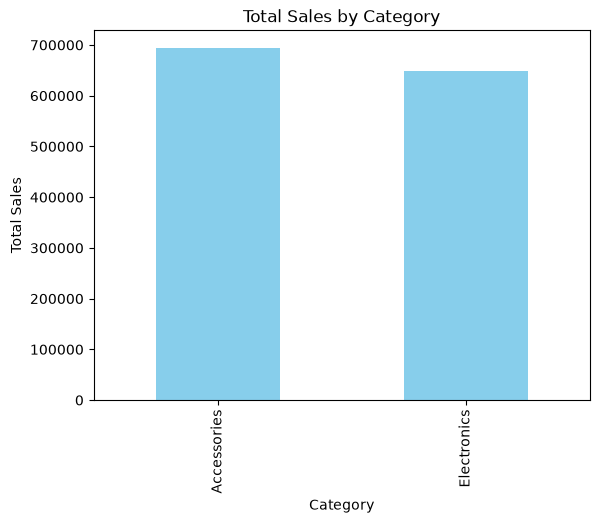

In [13]:
sales_by_category.plot(kind="bar", color="skyblue")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

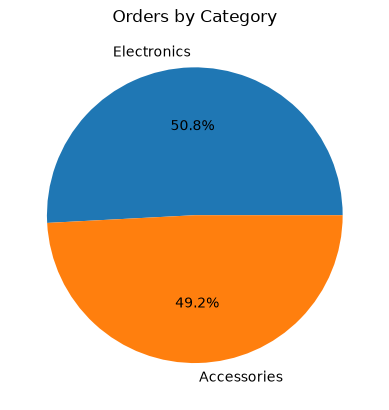

In [14]:
df["Category"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Orders by Category")
plt.ylabel("")
plt.show()

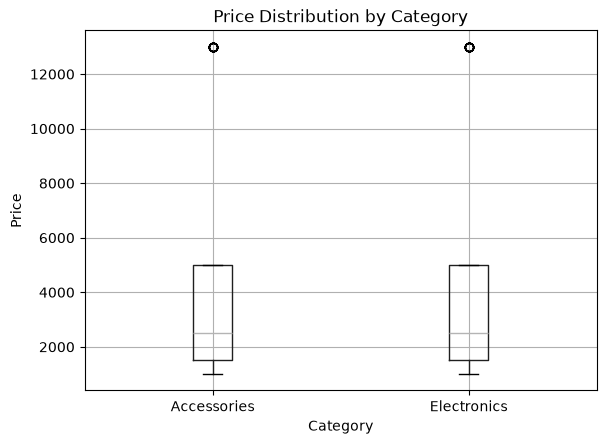

In [15]:
df.boxplot(column="Price", by="Category")
plt.title("Price Distribution by Category")
plt.suptitle("")
plt.xlabel("Category")
plt.ylabel("Price")
plt.show()